In [107]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('https://raw.githubusercontent.com/anvarnarz/praktikum_datasets/main/housing_data_08-02-2021.csv')
df.head()

,location,district,rooms,size,level,max_levels,price
0,"город Ташкент, Юнусабадский район, Юнусабад 8-...",Юнусабадский,3,57,4,4,52000
1,"город Ташкент, Яккасарайский район, 1-й тупик ...",Яккасарайский,2,52,4,5,56000
2,"город Ташкент, Чиланзарский район, Чиланзар 2-...",Чиланзарский,2,42,4,4,37000
3,"город Ташкент, Чиланзарский район, Чиланзар 9-...",Чиланзарский,3,65,1,4,49500
4,"город Ташкент, Чиланзарский район, площадь Актепа",Чиланзарский,3,70,3,5,55000


In [108]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7565 entries, 0 to 7564
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   location    7565 non-null   str  
 1   district    7565 non-null   str  
 2   rooms       7565 non-null   int64
 3   size        7565 non-null   str  
 4   level       7565 non-null   int64
 5   max_levels  7565 non-null   int64
 6   price       7565 non-null   str  
dtypes: int64(3), str(4)
memory usage: 413.8 KB


In [109]:
df.describe()

,rooms,level,max_levels
count,7565.000000,7565.000000,7565.000000
mean,2.625644,3.699273,6.038202
std,1.085201,2.237275,2.613271
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,4.000000
50%,3.000000,3.000000,5.000000
75%,3.000000,5.000000,9.000000
max,10.000000,19.000000,25.000000


In [110]:
df.dtypes

location        str
district        str
rooms         int64
size            str
level         int64
max_levels    int64
price           str
dtype: object

In [111]:
price_numeric = pd.to_numeric(df['price'], errors='coerce')

df.loc[price_numeric.isna(), 'price'].value_counts(dropna=False)

price
Договорная    99
Name: count, dtype: int64

In [112]:
df['price'] = pd.to_numeric(df['price'], errors='coerce')

In [113]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7565 entries, 0 to 7564
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location    7565 non-null   str    
 1   district    7565 non-null   str    
 2   rooms       7565 non-null   int64  
 3   size        7565 non-null   str    
 4   level       7565 non-null   int64  
 5   max_levels  7565 non-null   int64  
 6   price       7466 non-null   float64
dtypes: float64(1), int64(3), str(3)
memory usage: 413.8 KB


In [114]:
size_numeric = pd.to_numeric(df['size'], errors='coerce')

df.loc[size_numeric.isna(), 'size'].value_counts(dropna=False)

size
Площадьземли:1сот    1
Name: count, dtype: int64

In [115]:
df['size'] = pd.to_numeric(df['size'], errors='coerce')

In [116]:
df.dtypes

location          str
district          str
rooms           int64
size          float64
level           int64
max_levels      int64
price         float64
dtype: object

In [117]:
df.isnull().sum()

location       0
district       0
rooms          0
size           1
level          0
max_levels     0
price         99
dtype: int64

In [118]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percent': (df.isnull().sum() / len(df)) * 100
})

missing

,Missing_Count,Missing_Percent
location,0,0.000000
district,0,0.000000
rooms,0,0.000000
size,1,0.013219
level,0,0.000000
max_levels,0,0.000000
price,99,1.308658


In [119]:
df = df.dropna()

In [120]:
df.isnull().sum()

location      0
district      0
rooms         0
size          0
level         0
max_levels    0
price         0
dtype: int64

In [121]:
df.shape

(7465, 7)

In [122]:
df = df.reset_index(drop=True)

In [123]:
# nan qiymatlarni o'chirdik
# endi duplikatga tekshiramiz

df.duplicated().sum()

np.int64(697)

In [124]:
# duplikatlarni o'chiramiz

df = df.drop_duplicates()

In [125]:
# indeksni yangilab qoyamiz

df = df.reset_index(drop=True)

In [126]:
print('Dataset shape:', df.shape)
print('Duplicates:', df.duplicated().sum())

Dataset shape: (6768, 7)
Duplicates: 0


In [127]:
df.describe()

,rooms,size,level,max_levels,price
count,6768.000000,6768.000000,6768.000000,6768.000000,6.768000e+03
mean,2.623079,117.818163,3.706265,6.041371,7.271491e+04
std,1.075094,1576.459208,2.255645,2.619747,6.724904e+05
min,1.000000,1.000000,1.000000,1.000000,2.000000e+00
25%,2.000000,50.000000,2.000000,4.000000,3.500000e+04
50%,3.000000,66.000000,3.000000,5.000000,4.650000e+04
75%,3.000000,85.000000,5.000000,9.000000,6.700000e+04
max,10.000000,70000.000000,19.000000,25.000000,5.200000e+07


In [128]:
df.nlargest(10, 'size')[['district', 'rooms', 'size', 'price']]

,district,rooms,size,price
2426,Юнусабадский,3,70000.0,76000.0
4239,Олмазорский,4,69000.0,69000.0
4983,Мирзо-Улугбекский,3,67000.0,67000.0
2912,Мирзо-Улугбекский,2,44000.0,44000.0
2157,Мирзо-Улугбекский,1,24500.0,24500.0
6309,Олмазорский,4,7407.0,44000.0
936,Мирабадский,3,7359.0,46500.0
4388,Мирабадский,3,7359.0,46500.0
2538,Учтепинский,1,3448.0,25000.0
6648,Юнусабадский,8,2100.0,265000.0


In [151]:
df=df[df['size']<2000]

In [152]:
df.nlargest(10, 'price')[['district', 'rooms', 'size', 'price']]

,district,rooms,size,price
6344,Чиланзарский,2,85.0,6630000.0
6541,Яшнободский,4,96.0,5568000.0
5864,Юнусабадский,3,80.0,4240000.0
1667,Олмазорский,3,84.0,3780000.0
327,Яшнободский,2,68.0,1666000.0
6682,Чиланзарский,2,42.0,1470000.0
5533,Юнусабадский,3,42.0,1344000.0
1620,Мирабадский,10,456.0,800000.0
4520,Чиланзарский,1,28.0,644000.0
3398,Мирабадский,5,225.0,530000.0


In [161]:
df=df[df['price']<1000000]


In [162]:
numerical_cols = df.select_dtypes(include=np.number).columns
numerical_cols

Index(['rooms', 'size', 'level', 'max_levels', 'price'], dtype='str')

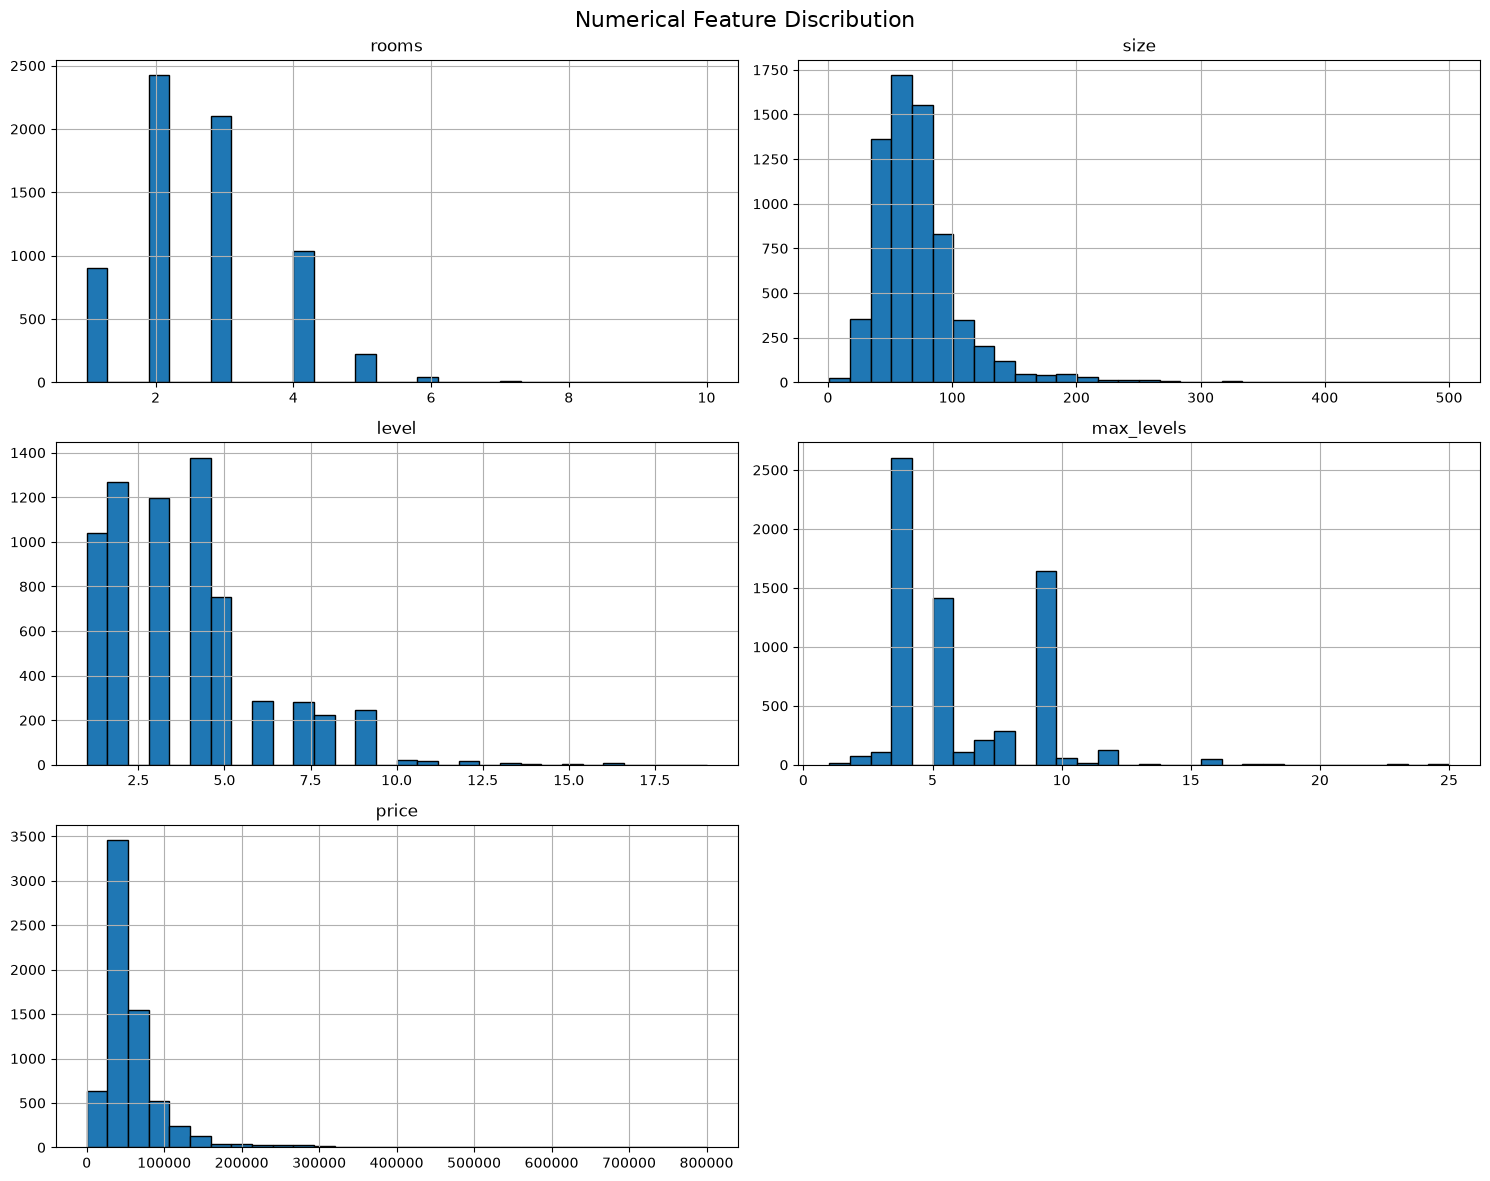

In [163]:
# Histogram orqali sonli ustunlar taqsimotini koramz

df[numerical_cols].hist(
    figsize=(15,12),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Numerical Feature Discribution', fontsize=16)
plt.tight_layout()
plt.show()

In [165]:
df.nlargest(10, 'size')[['district', 'rooms', 'size', 'price']]

,district,rooms,size,price
3787,Шайхантахурский,6,500.0,1800.0
1618,Яшнободский,4,456.0,230000.0
1620,Мирабадский,10,456.0,800000.0
1485,Юнусабадский,10,448.0,425600.0
4754,Шайхантахурский,6,420.0,200000.0
1746,Мирзо-Улугбекский,6,400.0,2000.0
2806,Яшнободский,7,360.0,300000.0
259,Мирабадский,8,350.0,260000.0
2266,Мирзо-Улугбекский,6,347.0,240000.0
6152,Шайхантахурский,6,341.0,250000.0


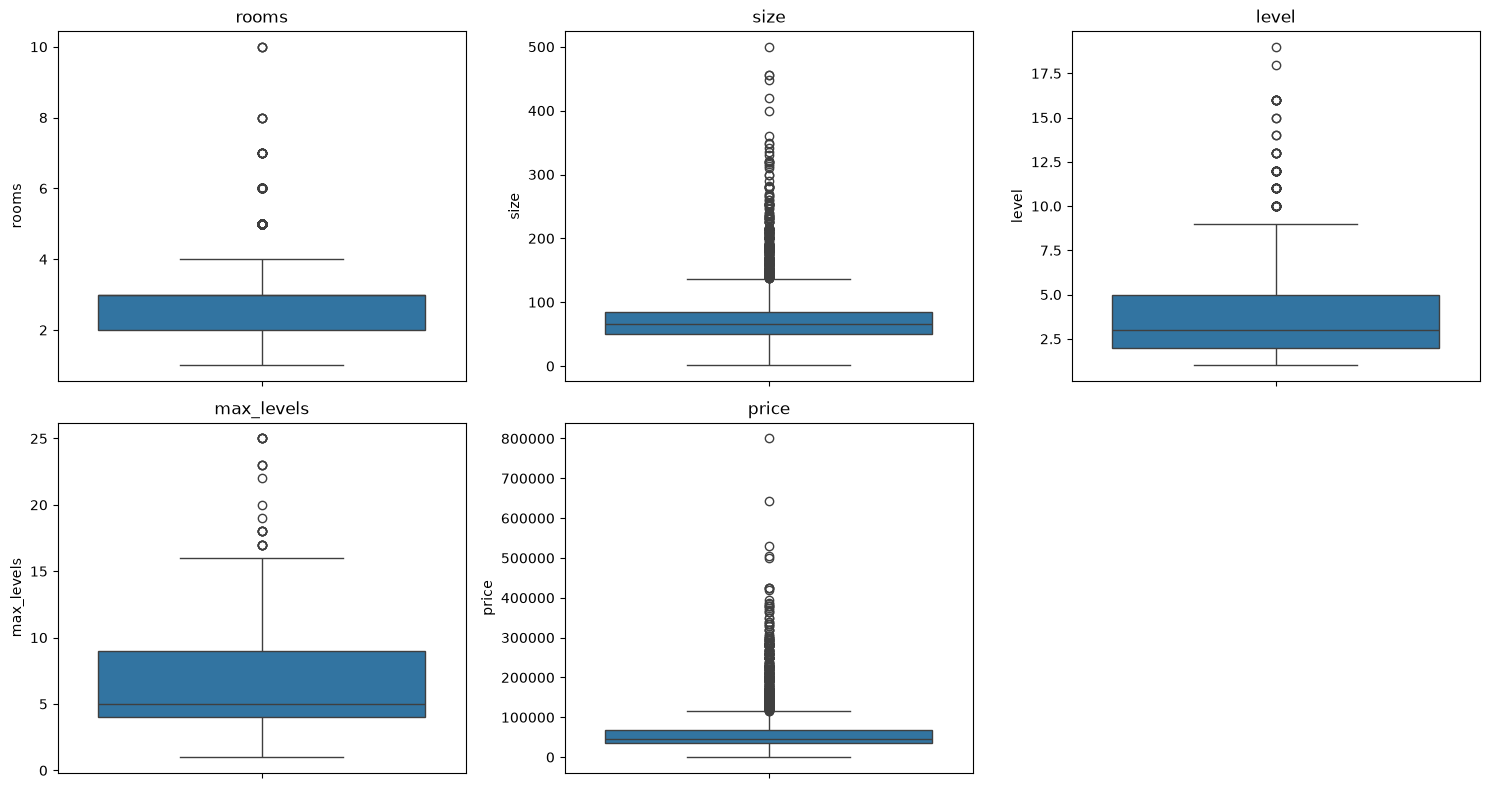

In [166]:
plt.figure(figsize=(15,8))

for i, col in enumerate(numerical_cols):
    plt.subplot(2,3,i+1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [169]:
df['district'].value_counts()

district
Чиланзарский         1475
Мирзо-Улугбекский    1206
Юнусабадский          810
Учтепинский           796
Мирабадский           699
Яккасарайский         554
Яшнободский           448
Шайхантахурский       342
Олмазорский           248
Сергелийский          149
Янгихаётский           14
Бектемирский            8
Name: count, dtype: int64

### correlation analysis

In [173]:
correlation = df[
    ['rooms', 'size', 'level', 'max_levels', 'price']
].corr()

correlation

,rooms,size,level,max_levels,price
rooms,1.000000,0.773199,0.139368,0.182786,0.548259
size,0.773199,1.000000,0.161489,0.271621,0.763310
level,0.139368,0.161489,1.000000,0.597967,0.066096
max_levels,0.182786,0.271621,0.597967,1.000000,0.226262
price,0.548259,0.763310,0.066096,0.226262,1.000000


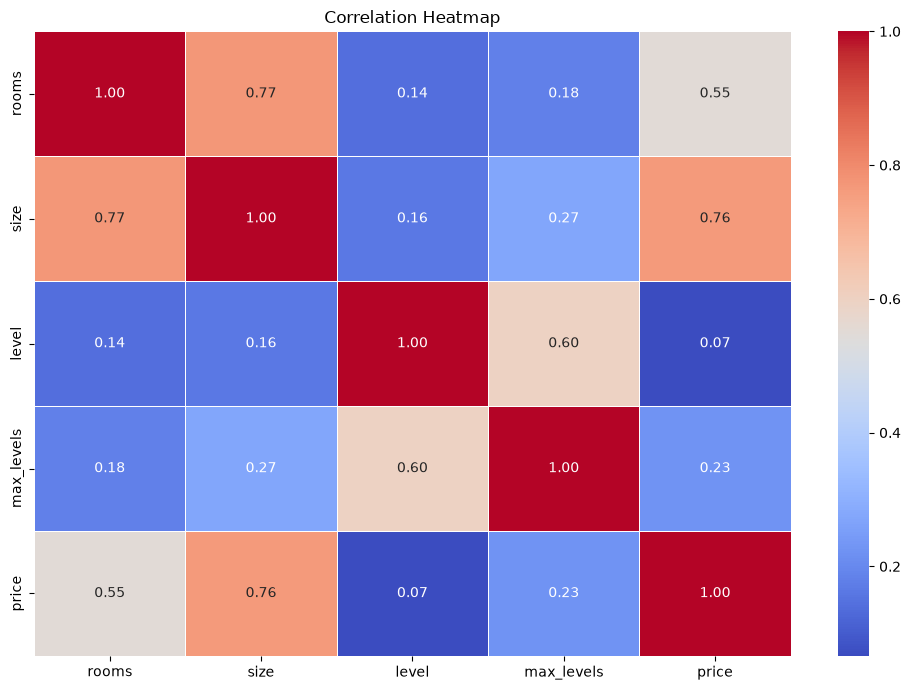

In [174]:
# Korrelyatsiyani grafikda korish

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### District boyicha uylarni narxi

In [175]:
district_price = df.groupby('district')['price'].mean().sort_values(ascending=False)
district_price

district
Мирабадский          96311.555079
Яккасарайский        73339.658845
Шайхантахурский      69050.994152
Юнусабадский         62326.037037
Мирзо-Улугбекский    58022.951907
Олмазорский          51869.048387
Яшнободский          50678.551339
Чиланзарский         46443.336949
Учтепинский          45008.287688
Сергелийский         43863.087248
Янгихаётский         37750.000000
Бектемирский         29462.500000
Name: price, dtype: float64

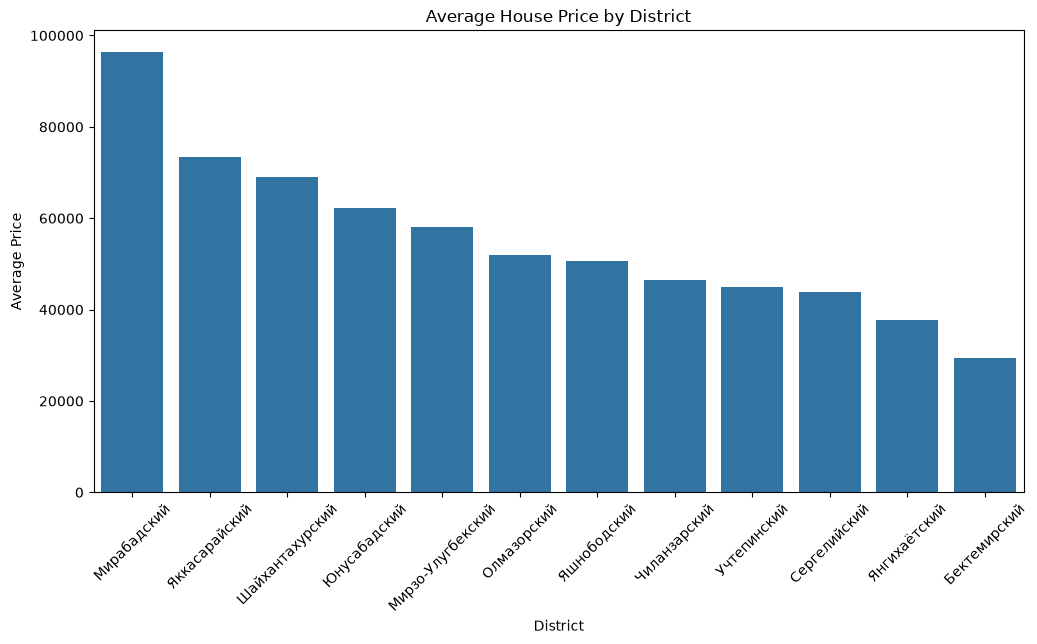

In [176]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=district_price.index,
    y=district_price.values
)

plt.xticks(rotation=45)
plt.title('Average House Price by District')
plt.xlabel('District')
plt.ylabel('Average Price')
plt.show()

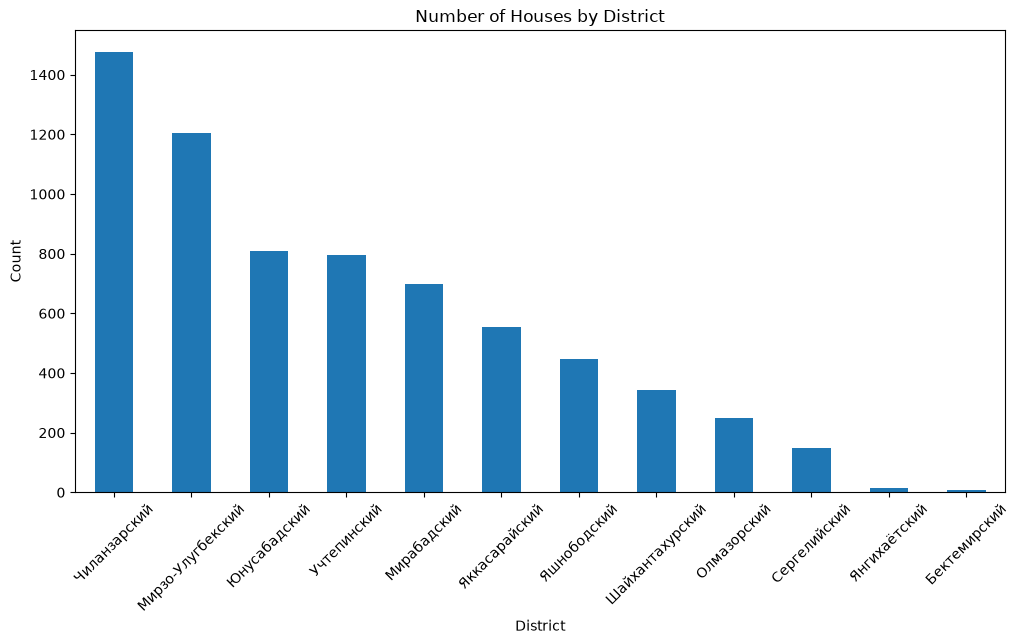

In [177]:
plt.figure(figsize=(12, 6))

df['district'].value_counts().plot(kind='bar')

plt.title('Number of Houses by District')
plt.xlabel('District')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

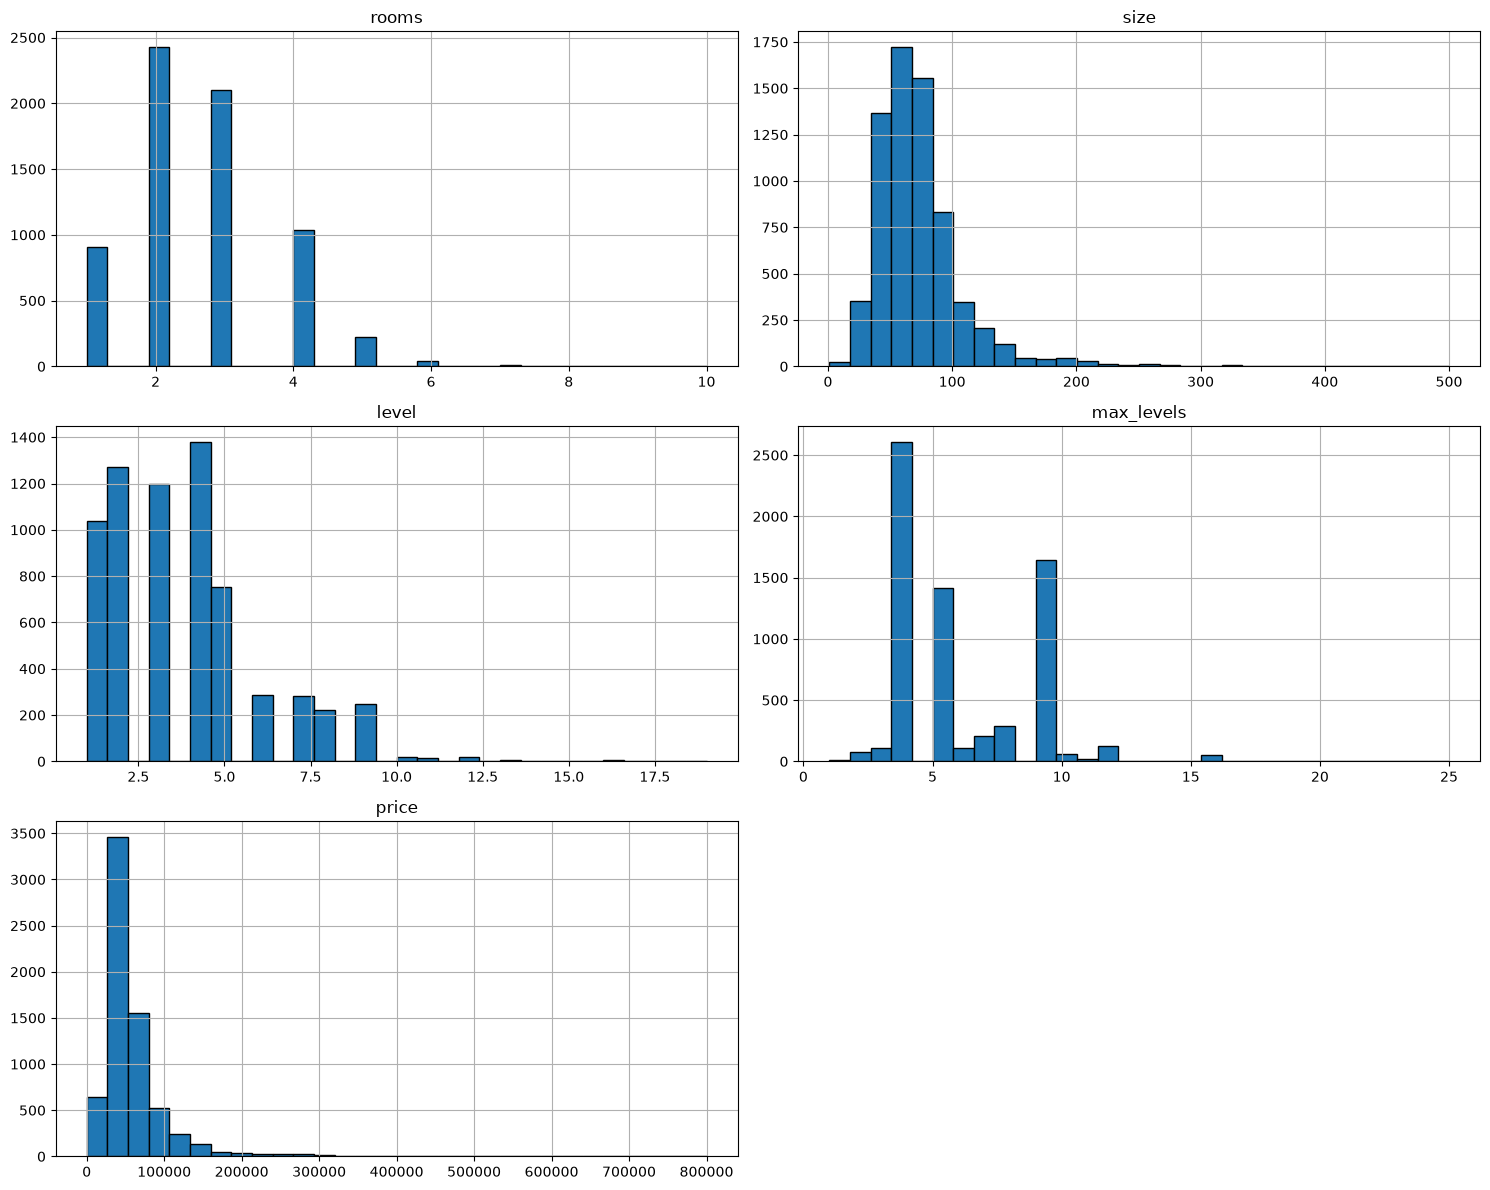

In [178]:
numerical_cols = df.select_dtypes(include='number').columns

df[numerical_cols].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor='black'
)

plt.tight_layout()
plt.show()